In [ ]:
!pip install pyqt5 numpy matplotlib termcolor

In [ ]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.9 kB/s  0:01:36 eta 0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]3 [ipywidgets]


# imports 

In [19]:
from collections import deque
import heapq
import math
import time
from itertools import count

GOAL = (0, 1, 2, 3, 4, 5, 6, 7, 8)

# Priorities

In [35]:
#Priorities bt3tna : Up, Down, Left, Right hsb refrence
NEIGHBORS = {
    0: [(3, 'Down'), (1, 'Right')],
    1: [(4, 'Down'), (0, 'Left'), (2, 'Right')],
    2: [(5, 'Down'), (1,'Left')],
    3: [(0,'Up'), (6,'Down'), (4,'Right')],
    4: [(1, 'Up'), (7, 'Down'), (3, 'Left'), (5, 'Right')],
    5: [(2,'Up'), (8,'Down'), (4,'Left')],
    6: [(3,'Up'), (7,'Right')],
    7: [(4,'Up'), (6,'Left'), (8,'Right')],
    8: [(5,'Up'),(7,'Left')]
}
moves = { #hasa nfs el neighbors bas msh mot2keda
    'Up': -3,  
    'Down': 3,   
    'Left': -1,  
    'Right': 1   
}

# Node datastucture

In [36]:
class Node:
    _counter = count()   # shared by all nodes

    def __init__(self, board, parent=None, move=None, depth=0, cost=0):
        self.board = board
        self.parent = parent
        self.move = move
        self.depth = depth
        self.cost = cost
        self.order = next(Node._counter)   # creation order

    def __lt__(self, other):
        return (self.cost, self.order) < (other.cost, other.order)



In [37]:
def swap(state, i, j):
    board = list(state)
    board[i], board[j] = board[j], board[i]
    return tuple(board)

def get_children(node):
    i = node.board.index(0)
    children = []
    for j, d in NEIGHBORS[i]:
        new_board = swap(node.board, i, j)
        child = Node(new_board, node, d, node.depth + 1)
        children.append(child)
    return children


In [38]:

#lw 3ozna length el path? len(moves)
def get_path(node):
    moves = []
    while node.parent != None:
        moves.append(node.move)   #han save
        node = node.parent      
    moves.reverse()               # gebna mn goal ll parent, ne3ks ba
    return moves


In [39]:

#shaklan helw bs, trust
def print_board(board):
    print("┌───┬───┬───┐")
    for r in range(3):
        row = board[r*3 : r*3+3]
        print("│" + "│".join(f" {t if t else ' '} " for t in row) + "│")
        if r < 2:
            print("├───┼───┼───┤")
    print("└───┴───┴───┘")


def print_solution(goal_node):
    nodes = []
    node = goal_node
    while node != None:
        nodes.append(node)
        node = node.parent
    nodes.reverse()

    print("Initial board:")
    print_board(nodes[0].board)

    for step, node in enumerate(nodes[1:], start=1):
        print(f"Step {step}: move {node.move}")
        print_board(node.board)

    print("Goal reached!")


In [40]:
def moveBlank(board, move, blank):
    return swap(board, blank, blank + moves[move])

In [41]:
def movePiece(board,move,blank):
    #move the number based on the move and change blacnk pos
    new = list(board)
    newBlank_position = blank + moves[move]
    new[blank],new[newBlank_position] = new[newBlank_position],new[blank]
    return tuple(new)

# Euclidean distance

In [42]:
def HeuristicsEuclidean(board):
    h = 0
    for i,t in enumerate(board):
        if t !=0: #malnash da3wa bl fadi
            x1,y1 = divmod(i,3) #current position
            x2,y2 = divmod(t,3) #goal position
            h += math.sqrt((x1-x2)**2 + (y1-y2)**2)
    return h

def AStarEuclidean(start):
    frontier = []
    explored = set()
    nodes_expanded = 0
    max_depth = 0
    heapq.heappush(frontier,Node(start, None, None, 0, HeuristicsEuclidean(start))) # put start node in heapq
    while frontier:
        current = heapq.heappop(frontier) # get the current with the lowest cost
        max_depth = max(max_depth, current.depth)



        if current.board == GOAL: # if goal reached
            return current, nodes_expanded, max_depth

        
        if current.board in explored:
            continue
        explored.add(tuple(current.board))
        nodes_expanded += 1                      # we expanded this board
        

        blank = current.board.index(0)
        
        for move in moves:
            #no illigal move
            if move =='Up' and blank < 3:
                continue
            if move =='Down' and blank > 5:
                continue
            if move =='Left' and blank % 3 == 0:
                continue
            if move =='Right' and blank % 3 == 2:
                continue
            # shift el Blank
            newboard = moveBlank(current.board, move, blank)
            if tuple(newboard) in explored:
                continue
            #next node
            new = Node(newboard,current,move,current.depth+1,HeuristicsEuclidean(newboard)+current.depth+1)
            heapq.heappush(frontier,new) #push in queue
    return None, nodes_expanded, max_depth

# Manhattan distance

In [43]:
def HeuristicsManhattan(board):
    h = 0
    for i, t in enumerate(board):
        if t != 0:  # ignore the blank
            x1, y1 = divmod(i, 3)  # current position
            x2, y2 = divmod(t, 3)  # goal position
            h += abs(x1 - x2) + abs(y1 - y2)
    return h



def AStarManhattan(start):
    frontier = []
    explored = set()
    nodes_expanded = 0
    max_depth = 0
    
    heapq.heappush(frontier, Node(start, None, None, 0, HeuristicsManhattan(start)))
    while frontier:
        current = heapq.heappop(frontier)
        max_depth = max(max_depth, current.depth)
        
        if current.board == GOAL:
            return current, nodes_expanded, max_depth

        if current.board in explored:  # already expanded, skip
            continue
        explored.add(tuple(current.board))
        nodes_expanded += 1                      # we expanded this board
        
        blank = current.board.index(0)


        for move in moves:
            if move == 'Up' and blank < 3:
                continue
            if move == 'Down' and blank > 5:
                continue
            if move == 'Left' and blank % 3 == 0:
                continue
            if move == 'Right' and blank % 3 == 2:
                continue

            newboard = moveBlank(current.board, move, blank)
            if tuple(newboard) in explored:
                continue
            new = Node(newboard, current, move, current.depth + 1,
                       HeuristicsManhattan(newboard) + current.depth + 1)
            heapq.heappush(frontier, new)
    return None, nodes_expanded, max_depth


# BFS

In [44]:
def BFS(start):
    Frontier = deque()
    explored = set()
    nodes_expanded = 0
    max_depth = 0

    Frontier.append(Node(start))
    while Frontier:
        current = Frontier.popleft()
        max_depth = max(max_depth, current.depth)

        if current.board == GOAL:
            return current, nodes_expanded, max_depth

        if current.board in explored:
            continue
        explored.add(tuple(current.board))
        nodes_expanded += 1

        blank = current.board.index(0)

        for move in moves:
            if move == 'Up' and blank < 3:
                continue
            if move == 'Down' and blank > 5:
                continue
            if move == 'Left' and blank % 3 == 0:
                continue
            if move == 'Right' and blank % 3 == 2:
                continue

            newboard = moveBlank(current.board, move, blank)
            if tuple(newboard) in explored:
                continue
            new_node = Node(newboard, current, move, current.depth + 1)
            Frontier.append(new_node)

    return None, nodes_expanded, max_depth


# DFS

In [93]:
def DFS(start):
    Frontier = [] # mafesh builtin stack in python so we use list as stack
    explored = set()
    nodes_expanded = 0
    max_depth = 0

    Frontier.append(Node(start))
    while Frontier:
        current = Frontier.pop()
        max_depth = max(max_depth, current.depth)

        if current.board == GOAL:
            return current, nodes_expanded, max_depth

        if current.board in explored:
            continue
        explored.add(tuple(current.board))
        nodes_expanded += 1

        blank = current.board.index(0)

        for move in reversed(list(moves.keys())):  # reverse the order of moves 3shan stack is LIFO
            if move == 'Up' and blank < 3:
                continue
            if move == 'Down' and blank > 5:
                continue
            if move == 'Left' and blank % 3 == 0:
                continue
            if move == 'Right' and blank % 3 == 2:
                continue

            newboard = moveBlank(current.board, move, blank)
            if tuple(newboard) in explored:
                continue
            new_node = Node(newboard, current, move, current.depth + 1)
            Frontier.append(new_node)

    return None, nodes_expanded, max_depth


# IDFS

In [94]:
def IDFS (start , limit ):
    Frontier = [] # mafesh builtin stack in python so we use list as stack
    explored = {} # ok le sbb ma el set kant btbwzo 
    nodes_expanded = 0
    max_depth = 0
    
    Frontier.append(Node(start))
    while Frontier:
        current = Frontier.pop()
        max_depth = max(max_depth, current.depth)
        if current.board == GOAL:
            return current, nodes_expanded, max_depth

        if current.depth == limit:
           continue 
        

        if current.board in explored and explored[current.board]<= current.depth:
            continue
        explored[current.board] = current.depth
        nodes_expanded += 1

        blank = current.board.index(0)
      

        for move in reversed(list(moves.keys())):  # reverse the order of moves 3shan stack is LIFO
            if move == 'Up' and blank < 3:
                continue
            if move == 'Down' and blank > 5:
                continue
            if move == 'Left' and blank % 3 == 0:
                continue
            if move == 'Right' and blank % 3 == 2:
                continue

            newboard = moveBlank(current.board, move, blank)
            new_node = Node(newboard, current, move, current.depth + 1)
            Frontier.append(new_node)

    return None, nodes_expanded, max_depth
    

In [95]:
def idfs(src,max_depth):
    totalN = 0
    deepst = 0
    for d in range(max_depth + 1):
        goal_node, expanded,depth = IDFS(src, d)
        totalN += expanded
        deepst = max(deepst, depth)
        if goal_node is not None:
            return goal_node, totalN, deepst
    return None,totalN, deepst
            

# RUNS

In [101]:
def run_manhattan(start):
    t0 = time.perf_counter()
    goal_node, expanded, depth = AStarManhattan(start)
    elapsed = time.perf_counter() - t0

    if goal_node is None:
        print("No solution")
        return
    path = get_path(goal_node)
    print_solution(goal_node)                    # every step printed
    print("Path to goal:", path)
    print("Cost of path:", len(path))            # each move costs 1
    print("Nodes expanded:", expanded)
    print("Search depth:", depth)
    print(f"Running time: {elapsed:.4f} s")
    return goal_node
def run_idfs(start,limit =50):
    t0 = time.perf_counter()
    goal_node, expanded, depth = idfs(start, limit)
    elapsed = time.perf_counter() - t0

    if goal_node is None:
        print("No solution")
        return
    path = get_path(goal_node)
    print_solution(goal_node)                    # every step printed
    print("Path to goal:", path)
    print("Cost of path:", len(path))            # each move costs 1
    print("Nodes expanded:", expanded)
    print("Search depth:", depth)
    print(f"Running time: {elapsed:.4f} s")
    return goal_node

def run_euclidean(start):
    t0 = time.perf_counter()
    goal_node, expanded, depth = AStarEuclidean(start)
    elapsed = time.perf_counter() - t0

    if goal_node is None:
        print("No solution")
        return
    path = get_path(goal_node)
    print_solution(goal_node)                    # every step printed
    print("Path to goal:", path)
    print("Cost of path:", len(path))            # each move costs 1
    print("Nodes expanded:", expanded)
    print("Search depth:", depth)
    print(f"Running time: {elapsed:.4f} s")
    return goal_node

def run_bfs(start):
    t0 = time.perf_counter()
    goal_node, expanded, depth = BFS(start)
    elapsed = time.perf_counter() - t0

    if goal_node is None:
        print("No solution")
        return
    path = get_path(goal_node)
    print_solution(goal_node)                    # every step printed
    print("Path to goal:", path)
    print("Cost of path:", len(path))            # each move costs 1
    print("Nodes expanded:", expanded)
    print("Search depth:", depth)
    print(f"Running time: {elapsed:.4f} s")
    return goal_node

def run_dfs(start):
    t0 = time.perf_counter()
    goal_node, expanded, depth = DFS(start)
    elapsed = time.perf_counter() - t0

    if goal_node is None:
        print("No solution")
        return
    path = get_path(goal_node)
    print_solution(goal_node)                    # every step printed
    print("Path to goal:", path)
    print("Cost of path:", len(path))            # each move costs 1
    print("Nodes expanded:", expanded)
    print("Search depth:", depth)
    print(f"Running time: {elapsed:.4f} s")
    return goal_node

In [102]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyBboxPatch, Rectangle
import matplotlib
import pynput
import keyboard
#kan msh beyet7rk
matplotlib.use('QtAgg')
from time import sleep
from IPython.display import display, clear_output



def cell_xy(index):
    row,col=divmod(index,3)
    return col,2-row
def cleanAnimation(t):
    #smooth
    return t*t*(3-2*t)
def cute_animation_for_puzzle(gnode,framespm=12,intervals=30,holdf=30):
    

    nodes=[]
    node=gnode
    #start from node then retrace all moves append f array 
    while node is not None:
        nodes.append(node)
        node=node.parent
    nodes.reverse()
    boards=[n.board for n in nodes]
    moves=[n.move for n in nodes]
    nmoves =len(boards) -1
    fig,ax=plt.subplots(figsize=(6,6))
    #border
    fig.patch.set_facecolor('purple')
    #background
    ax.set_facecolor('pink')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(0,3)
    ax.set_ylim(0,3)
    ax.set_aspect('equal')
    #el border el rofya3 el f nos
    ax.spines['bottom'].set_color('white')
    ax.spines['top'].set_color('white')
    ax.spines['right'].set_color('white')
    ax.spines['left'].set_color('white')
    pad = 0.06
    tiles={}
  
 

    for i in range(1,9):
        x,y=cell_xy(boards[0].index(i))
        #rounded box el gowa el haytktb feh el rkm
        patch=FancyBboxPatch((x+pad,y+pad),1-2*pad,1-2*pad,boxstyle='round,pad=0,rounding_size=0.15',facecolor='white',edgecolor='white',linewidth=2)
        ax.add_patch(patch)
        #el rkm el gowa
        text = ax.text(x+0.5,y+0.5,str(i),color='black',fontsize=20,fontweight='bold',va='center',ha='center')
        tiles[i]=(patch,text)
    for i in range(nmoves):
        for j in range(1,framespm+1):
            t=cleanAnimation(j/framespm)
            for k in range(1,9):
                #position of each tile
                x0,y0=cell_xy(boards[i].index(k))
                x1,y1=cell_xy(boards[i+1].index(k))
                x=x0+(x1-x0)*t
                y=y0+(y1-y0)*t
                patch,text=tiles[k]
                patch.set_x(x+pad)
                patch.set_y(y+pad)
                text.set_position((x+0.5,y+0.5))
        
        
            clear_output(wait=True)
            display(fig)
            sleep(intervals / 1000)

    ax.set_title("Goal reached!", color='white')
    clear_output(wait=True)
    display(fig)
    plt.close(fig)

In [103]:
%matplotlib inline





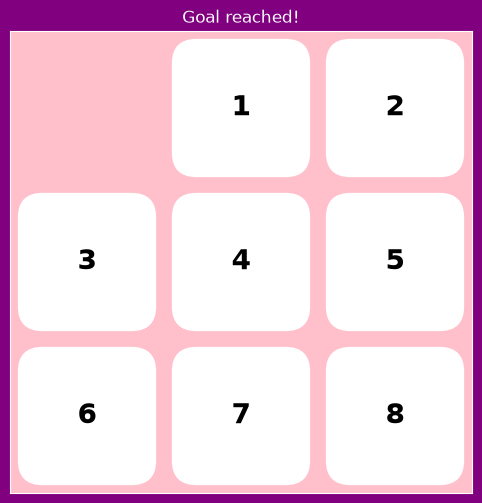

In [105]:
def solvable(board):
    inversions = 0
    for i in range(len(board)):
        for j in range(i+1, len(board)):
            if board[i] > board[j] and board[i] != 0 and board[j] != 0:
                inversions += 1
    return inversions % 2 == 0

#mesh ana eli 3mla el test
inputStart = input("write input array")
if not inputStart :
    start = (8, 0, 6, 5, 4, 7, 2, 3, 1)
else: 
    digits = inputStart.replace(",", " ").split()
    if len(digits) != 9:
        print("Invalid input. Please enter exactly 9 digits.")
    else:
        start = tuple(int(digit) for digit in digits)
        if sorted(start) != list(GOAL):
            print("Invalid input")
        else:
            start = tuple(start)
if not solvable(start):
    print("error: not solvable")
else:
    choice = input("which algorithim (euclidean/manhattan/BFS/DFS):").strip()
    choose_runners ={
        "euclidean": run_euclidean,
        "manhattan": run_manhattan,
        "BFS": run_bfs,
        "DFS": run_dfs,
        "IDFS": run_idfs
        

    }
    if choice in choose_runners:
        if choose_runners[choice] == run_idfs:
            max_depth = int(input("enter max depth:"))
            solution = choose_runners[choice](start, max_depth)
        else:
            solution = choose_runners[choice](start)
        if solution:
            print(f"{choice} solution: {solution}")
            cute_animation_for_puzzle(solution)
        else:
            print(f"No solution found for {choice}")
    else:
        print("Invalid choice")

    # Test 1: children of the start (expect 3: Up, Down, Left)
    
       

